In [ ]:

!pip install transformers torch scikit-learn

In [ ]:
!pip install "datasets<2.20.0"

INFO: pip is looking at multiple versions of multiprocess to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 542.1/542.1 kB 28.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 116.3/116.3 kB 8.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 172.0/172.0 kB 14.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 146.7/146.7 kB 9.2 MB/s eta 0:00:00
  Attempting uninstall: fsspec
    Found existing installation: fsspec 2025.12.0
    Uninstalling fsspec-2025.12.0:
      Successfully uninstalled fsspec-2025.12.0
  Attempting uninstall: dill
    Found existing installation: dill 0.4.1
    Uninstalling dill-0.4.1:
      Successfully uninstalled dill-0.4.1
  Attempting uninstall: multiprocess
    Found existing installation: multiprocess 0.70.19
    Uninstalling multiprocess-0.70.19:
      Successfully uninstalled multiprocess-0.70.19
  Attempting uninstall: datasets
    Fo

In [ ]:
!pip install lime

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 275.7/275.7 kB 9.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=46900460d38018f34ed42c7cdb1378521ee0aaa667c3b71737e2a8b2f8526f81
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime


In [ ]:
!pip install  matplotlib seaborn


In [ ]:
# fixando as sementes
import os
import random
import re
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from transformers import BertTokenizer
from datasets import load_dataset
from lime.lime_text import LimeTextExplainer

def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    os.environ['PYTHONHASHSEED'] = str(seed)
    print(f"[OK] semente  fixada em: {seed}")

set_seed(42)


[OK] Semente global fixada em: 42


In [ ]:
print("Baixando os arquivos ")
dataset_train = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"train": "mental_heath_unbanlanced.csv"})
dataset_test = load_dataset("ourafla/Mental-Health_Text-Classification_Dataset", data_files={"test": "mental_health_combined_test.csv"})
df_train = pd.DataFrame(dataset_train['train'])
df_test = pd.DataFrame(dataset_test['test'])

# Consolida a base
df_total = pd.concat([df_train, df_test], ignore_index=True)
df_total = df_total[df_total['status'].isin(['Depression', 'Normal'])].copy()
df_total['label'] = df_total['status'].map({'Normal': 0, 'Depression': 1})
df_total = df_total.rename(columns={'text': 'texto_limpo'})

def limpar_texto_redes_sociais(texto):
    if not isinstance(texto, str):
        return ""
    texto = texto.lower()
    texto = re.sub(r'http\S+|www\S+|https\S+', '', texto, flags=re.MULTILINE)
    texto = re.sub(r'\@\w+', '', texto)
    texto = re.sub(r'[^\w\s]', '', texto)
    texto = re.sub(r'\s+', ' ', texto).strip()
    return texto

print("limpando")
df_total['texto_limpo'] = df_total['texto_limpo'].apply(limpar_texto_redes_sociais)

# remove as duplicatas
qtd_antes = len(df_total)
df_total = df_total[df_total['texto_limpo'].str.len() > 5].copy()
df_total = df_total.drop_duplicates(subset=['texto_limpo']).reset_index(drop=True)
qtd_depois = len(df_total)

print(f"Total final de registros: {qtd_depois}")

Baixando os arquivos 


Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

limpando
Total final de registros: 32601


In [ ]:
# dividindo os dados
df_treino, df_teste = train_test_split(
    df_total,
    test_size=0.20,
    random_state=42,
    stratify=df_total['label']
)

print(f"Treino: {len(df_treino)} | Teste: {len(df_teste)}")

print("tokenizando os textos com o BertTokenizer")
tokenizer = BertTokenizer.from_pretrained('bert-base-uncased')

train_encodings = tokenizer(df_treino['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)
test_encodings = tokenizer(df_teste['texto_limpo'].tolist(), truncation=True, padding='max_length', max_length=128)

print("Tokenização concluída")

Treino: 26080 | Teste: 6521
tokenizando os textos com o BertTokenizer


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Tokenização concluída


In [ ]:
textos_treino = set(df_treino["texto_limpo"])
textos_teste = set(df_teste["texto_limpo"])
interseccao = textos_treino.intersection(textos_teste)


print("TESTE DE INTEGRIDADE ")

print(f"Textos únicos no Treino: {len(textos_treino)}")
print(f"Textos únicos no Teste: {len(textos_teste)}")
print(f"Quantidade de textos IDÊNTICOS em ambos: {len(interseccao)}")

if len(interseccao) == 0:
  print(
      "\n O conjunto de teste está 100% limpo e sem vazamento de"
      " dados."
  )
else:
  print(
      f"\nATENÇÃO! Encontrados {len(interseccao)} textos duplicados entre"
      " treino e teste!"
  )
  print("Amostra dos textos vazados:")
  for i, texto in enumerate(list(interseccao)[:3], 1):
    print(f" {i}. {repr(texto)}")

TESTE DE INTEGRIDADE 
Textos únicos no Treino: 26080
Textos únicos no Teste: 6521
Quantidade de textos IDÊNTICOS em ambos: 0

 O conjunto de teste está 100% limpo e sem vazamento de dados.


In [ ]:
# organizando os dados
class OuraflaDataset(Dataset):

  def __init__(self, encodings, labels):
    self.encodings = encodings
    self.labels = labels

  def __getitem__(self, idx):
    item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
    item["labels"] = torch.tensor(self.labels[idx], dtype=torch.long)
    return item

  def __len__(self):
    return len(self.labels)


print("criando os objetos Dataset ")
train_dataset = OuraflaDataset(train_encodings, df_treino["label"].tolist())
test_dataset = OuraflaDataset(test_encodings, df_teste["label"].tolist())

print("empacotando os dados em lotes (Batch Size = 32)")
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

print(
    f" Treino: {len(train_loader)} lotes | Teste:"
    f" {len(test_loader)} lotes.\n"
)

print("Inspeção do Primeiro Lote")
primeiro_lote = next(iter(train_loader))
print("Chaves contidas no lote:     ", primeiro_lote.keys())
print("Dimensão dos input_ids:      ", primeiro_lote["input_ids"].shape)
print("Dimensão da attention_mask:  ", primeiro_lote["attention_mask"].shape)
print("Dimensão dos rótulos:        ", primeiro_lote["labels"].shape)
print("\nRótulos das 32 amostras deste lote (0 = Normal, 1 = Depressão):")
print(primeiro_lote["labels"])

criando os objetos Dataset 
empacotando os dados em lotes (Batch Size = 32)
 Treino: 815 lotes | Teste: 204 lotes.

Inspeção do Primeiro Lote
Chaves contidas no lote:      dict_keys(['input_ids', 'token_type_ids', 'attention_mask', 'labels'])
Dimensão dos input_ids:       torch.Size([32, 128])
Dimensão da attention_mask:   torch.Size([32, 128])
Dimensão dos rótulos:         torch.Size([32])

Rótulos das 32 amostras deste lote (0 = Normal, 1 = Depressão):
tensor([0, 0, 1, 0, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1,
        0, 1, 0, 1, 0, 0, 0, 1])


In [ ]:
# arquitetura bert
class BERTEmbeddings(nn.Module):

  def __init__(self, vocab_size=30522, hidden_size=768, max_len=512):
    super().__init__()
    self.word_embeddings = nn.Embedding(vocab_size, hidden_size)
    self.position_embeddings = nn.Embedding(max_len, hidden_size)
    self.segment_embeddings = nn.Embedding(2, hidden_size)
    self.layer_norm = nn.LayerNorm(hidden_size)
    self.dropout = nn.Dropout(0.1)

  def forward(self, input_ids, token_type_ids):
    seq_len = input_ids.size(1)
    position_ids = (
        torch.arange(seq_len, dtype=torch.long, device=input_ids.device)
        .unsqueeze(0)
    )
    embeddings = (
        self.word_embeddings(input_ids)
        + self.position_embeddings(position_ids)
        + self.segment_embeddings(token_type_ids)
    )
    return self.dropout(self.layer_norm(embeddings))


class SelfAttention(nn.Module):

  def __init__(self, hidden_size=768, num_heads=12):
    super().__init__()
    self.num_heads = num_heads
    self.head_dim = hidden_size // num_heads
    self.query = nn.Linear(hidden_size, hidden_size)
    self.key = nn.Linear(hidden_size, hidden_size)
    self.value = nn.Linear(hidden_size, hidden_size)
    self.fc_out = nn.Linear(hidden_size, hidden_size)

  def forward(self, x, mask=None):
    N, length, _ = x.shape
    Q = (
        self.query(x)
        .reshape(N, length, self.num_heads, self.head_dim)
        .transpose(1, 2)
    )
    K = (
        self.key(x)
        .reshape(N, length, self.num_heads, self.head_dim)
        .transpose(1, 2)
    )
    V = (
        self.value(x)
        .reshape(N, length, self.num_heads, self.head_dim)
        .transpose(1, 2)
    )

    energy = torch.matmul(Q, K.transpose(-2, -1)) / np.sqrt(self.head_dim)
    if mask is not None:
      energy = energy.masked_fill(mask.unsqueeze(1).unsqueeze(2) == 0, -1e9)

    attention = torch.softmax(energy, dim=-1)
    out = (
        torch.matmul(attention, V)
        .transpose(1, 2)
        .reshape(N, length, self.num_heads * self.head_dim)
    )
    return self.fc_out(out)


class TransformerBlock(nn.Module):

  def __init__(self, hidden_size=768, num_heads=12):
    super().__init__()
    self.attention = SelfAttention(hidden_size, num_heads)
    self.norm1 = nn.LayerNorm(hidden_size)
    self.norm2 = nn.LayerNorm(hidden_size)
    self.feed_forward = nn.Sequential(
        nn.Linear(hidden_size, 3072), nn.GELU(), nn.Linear(3072, hidden_size)
    )
    self.dropout = nn.Dropout(0.1)

  def forward(self, x, mask=None):
    x = self.norm1(x + self.dropout(self.attention(x, mask)))
    return self.norm2(x + self.dropout(self.feed_forward(x)))


class BERT(nn.Module):

  def __init__(self, vocab_size=30522, hidden_size=768, num_layers=12):
    super().__init__()
    self.embeddings = BERTEmbeddings(vocab_size, hidden_size)
    self.encoder = nn.ModuleList(
        [TransformerBlock(hidden_size, 12) for _ in range(num_layers)]
    )

  def forward(self, input_ids, token_type_ids, mask=None):
    x = self.embeddings(input_ids, token_type_ids)
    for layer in self.encoder:
      x = layer(x, mask)
    return x


class BERTClassificadorDoZero(nn.Module):

  def __init__(self, hidden_size=768, num_classes=2):
    super().__init__()
    self.bert = BERT()
    self.classificador = nn.Linear(hidden_size, num_classes)

  def forward(self, input_ids, attention_mask):
    segment_ids = torch.zeros_like(input_ids)
    saida_bert = self.bert(input_ids, segment_ids, mask=attention_mask)
    return self.classificador(saida_bert[:, 0, :])


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"instanciando  no dispositivo: {device}")
meu_modelo = BERTClassificadorDoZero().to(device)

instanciando  no dispositivo: cuda


In [ ]:
# treinamento
criterio_perda = nn.CrossEntropyLoss()
otimizador = AdamW(meu_modelo.parameters(), lr=2e-5)
epochs = 3

print("iniciando o treinamento")
for epoch in range(epochs):
  meu_modelo.train()
  total_loss = 0
  for lote_idx, batch in enumerate(train_loader):
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    otimizador.zero_grad()
    previsoes = meu_modelo(input_ids, attention_mask)
    loss = criterio_perda(previsoes, labels)
    total_loss += loss.item()

    loss.backward()
    otimizador.step()

    if lote_idx % 100 == 0:
      print(
          f"Época {epoch + 1}/{epochs} | Lote {lote_idx}/{len(train_loader)} |"
          f" Loss: {loss.item():.4f}"
      )

  print(
      f"--- Fim da Época {epoch + 1} | Perda Média:"
      f" {total_loss / len(train_loader):.4f} ---"
  )

print("treinamento concluído")

iniciando o treinamento
Época 1/3 | Lote 0/815 | Loss: 0.7858
Época 1/3 | Lote 100/815 | Loss: 0.3642
Época 1/3 | Lote 200/815 | Loss: 0.3420
Época 1/3 | Lote 300/815 | Loss: 0.3003
Época 1/3 | Lote 400/815 | Loss: 0.3024
Época 1/3 | Lote 500/815 | Loss: 0.5604
Época 1/3 | Lote 600/815 | Loss: 0.2761
Época 1/3 | Lote 700/815 | Loss: 0.1280
Época 1/3 | Lote 800/815 | Loss: 0.0961
--- Fim da Época 1 | Perda Média: 0.2746 ---
Época 2/3 | Lote 0/815 | Loss: 0.1242
Época 2/3 | Lote 100/815 | Loss: 0.1049
Época 2/3 | Lote 200/815 | Loss: 0.3099
Época 2/3 | Lote 300/815 | Loss: 0.1156
Época 2/3 | Lote 400/815 | Loss: 0.4111
Época 2/3 | Lote 500/815 | Loss: 0.2194
Época 2/3 | Lote 600/815 | Loss: 0.1307
Época 2/3 | Lote 700/815 | Loss: 0.1021
Época 2/3 | Lote 800/815 | Loss: 0.3279
--- Fim da Época 2 | Perda Média: 0.1983 ---
Época 3/3 | Lote 0/815 | Loss: 0.2313
Época 3/3 | Lote 100/815 | Loss: 0.1575
Época 3/3 | Lote 200/815 | Loss: 0.1561
Época 3/3 | Lote 300/815 | Loss: 0.0907
Época 3/3 | 

Acurácia Global: 92.59%

               precision    recall  f1-score   support

   Normal (0)       0.95      0.91      0.93      3617
Depressão (1)       0.89      0.95      0.92      2904

     accuracy                           0.93      6521
    macro avg       0.92      0.93      0.93      6521
 weighted avg       0.93      0.93      0.93      6521



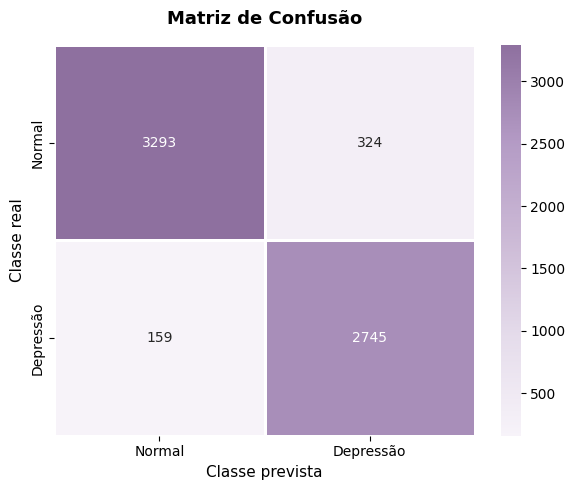

In [ ]:
#avaliação
meu_modelo.eval()
previsoes_finais, rotulos_reais = [], []

with torch.no_grad():
  for batch in test_loader:
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    logits = meu_modelo(input_ids, attention_mask)
    preds = torch.argmax(logits, dim=1)

    previsoes_finais.extend(preds.cpu().numpy())
    rotulos_reais.extend(labels.cpu().numpy())

acuracia = accuracy_score(rotulos_reais, previsoes_finais)


print(f"Acurácia Global: {acuracia * 100:.2f}%\n")
print(
    classification_report(
        rotulos_reais,
        previsoes_finais,
        target_names=["Normal (0)", "Depressão (1)"],
    )
)

cm = confusion_matrix(rotulos_reais, previsoes_finais)
cmap_bert2 = LinearSegmentedColormap.from_list(
    "BERT2", ["#F7F3F9", "#E5DCEB", "#CCBAD6", "#B49BC5", "#8E709F"]
)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap=cmap_bert2,
    xticklabels=["Normal", "Depressão"],
    yticklabels=["Normal", "Depressão"],
    linewidths=1,
    linecolor="white",
)
plt.xlabel("Classe prevista", fontsize=11)
plt.ylabel("Classe real", fontsize=11)
plt.title(
    "Matriz de Confusão",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.tight_layout()
plt.show()

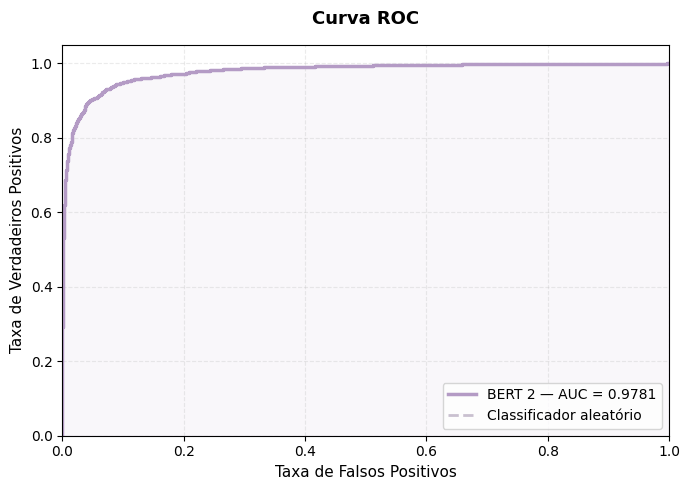

AUC Final: 0.9781


In [ ]:
# curva ROC
probabilidades, verdadeiros = [], []
meu_modelo.eval()

with torch.no_grad():
  for batch in test_loader:
    input_ids = batch["input_ids"].to(device)
    attention_mask = batch["attention_mask"].to(device)
    labels = batch["labels"].to(device)

    logits = meu_modelo(input_ids, attention_mask)
    probs = F.softmax(logits, dim=1)

    probabilidades.extend(probs[:, 1].cpu().numpy())
    verdadeiros.extend(labels.cpu().numpy())

fpr, tpr, limiares = roc_curve(verdadeiros, probabilidades)
roc_auc = auc(fpr, tpr)

plt.figure(figsize=(7, 5))
plt.plot(
    fpr, tpr, color="#B49BC5", lw=2.5, label=f"BERT 2 — AUC = {roc_auc:.4f}"
)
plt.fill_between(fpr, tpr, alpha=0.08, color="#B49BC5")
plt.plot(
    [1],
    color="#C9C0CF",
    lw=2,
    linestyle="--",
    label="Classificador aleatório",
)
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("Taxa de Falsos Positivos", fontsize=11)
plt.ylabel("Taxa de Verdadeiros Positivos", fontsize=11)
plt.title(
    "Curva ROC", fontsize=13, fontweight="bold", pad=15
)
plt.legend(loc="lower right", frameon=True)
plt.grid(alpha=0.25, linestyle="--")
plt.tight_layout()
plt.show()

print(f"AUC Final: {roc_auc:.4f}")

Texto analisado (amostra #72):
time to sleep again good morning everyone

Rótulo real: 0 (Normal)



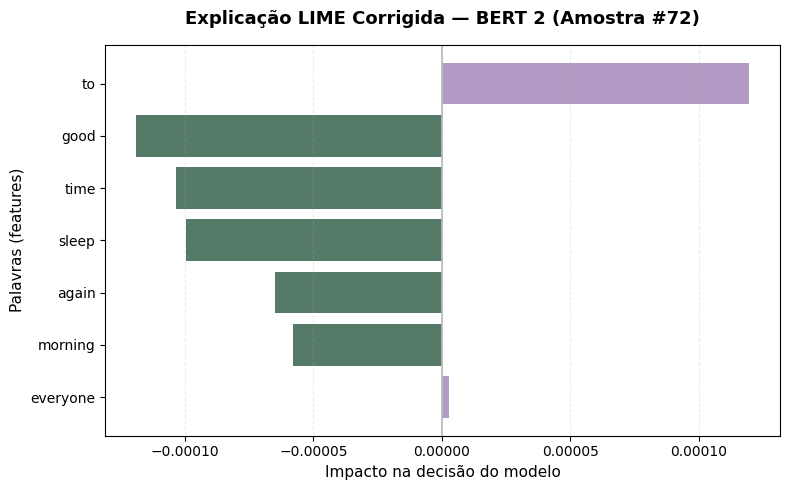

In [ ]:
#lime
def predict_probs_lime(texts):
  meu_modelo.eval()
  todas_probs = []
  for i in range(0, len(texts), 32):
    lote_textos = texts[i : i + 32]
    inputs = tokenizer(
        lote_textos,
        padding="max_length",
        truncation=True,
        max_length=128,
        return_tensors="pt",
    )
    input_ids = inputs["input_ids"].to(device)
    attention_mask = inputs["attention_mask"].to(device)
    with torch.no_grad():
      logits = meu_modelo(input_ids, attention_mask)
      probs = F.softmax(logits, dim=1)
      todas_probs.append(probs.cpu().numpy())
  return np.vstack(todas_probs)


explainer = LimeTextExplainer(
    class_names=["Normal", "Depressão"], random_state=42
)

idx = 72
texto_amostra = str(df_teste.iloc[idx]["texto_limpo"])
rotulo_real = int(df_teste.iloc[idx]["label"])

print(f"Texto analisado (amostra #{idx}):\n{texto_amostra}\n")
print(
    f"Rótulo real: {rotulo_real}"
    f" ({'Depressão' if rotulo_real == 1 else 'Normal'})\n"
)

exp = explainer.explain_instance(
    texto_amostra, predict_probs_lime, num_features=10, num_samples=500
)

lista_features = exp.as_list()
palavras = [item[0] for item in lista_features]
pesos = np.array([item[1] for item in lista_features])

plt.figure(figsize=(8, 5))
cores = ["#B49BC5" if peso > 0 else "#557A68" for peso in pesos]
plt.barh(palavras[::-1], pesos[::-1], color=cores[::-1])
plt.axvline(0, color="#B8B8B8", linewidth=1.2)
plt.xlabel("Impacto na decisão do modelo", fontsize=11)
plt.ylabel("Palavras (features)", fontsize=11)
plt.title(
    f"Explicação LIME (Amostra #{idx})",
    fontsize=13,
    fontweight="bold",
    pad=15,
)
plt.grid(axis="x", linestyle="--", alpha=0.25)
plt.tight_layout()
plt.show()